# 🍷 Tech Challenge Fase 2 — Classificação da Qualidade de Vinhos
## Notebook 04 · Interpretação dos Resultados

Etapa 6 do desafio:
- **Quais variáveis têm maior influência na qualidade do vinho?**
- **Quais as implicações para o processo de produção?**

Usamos três lentes complementares, para não depender de um único método:
1. **Coeficientes da Regressão Logística** (modelo final) — direção e intensidade de cada efeito, com intervalos de confiança por *bootstrap*.
2. **Importância por permutação** nos três modelos — quanto o desempenho cai quando "embaralhamos" cada variável. Se modelos diferentes concordam, o achado é robusto.
3. **Simulações "e se"** — como a pontuação do modelo muda quando ajustamos uma característica do vinho.

In [1]:
import sys, warnings
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.inspection import permutation_importance

from src.config import RESULTS_DIR, FEATURE_LABELS_PT, RANDOM_STATE
from src.modeling import MODEL_NAMES_PT
from src.visualization import set_style, save_fig, COLOR_LOW, COLOR_HIGH, COLOR_ACCENT, INK_2

set_style()
pd.set_option("display.float_format", "{:.3f}".format)

art = joblib.load(RESULTS_DIR / "models" / "modeling_artifacts.joblib")
tuned, thresholds = art["tuned"], art["thresholds"]
X_train, X_test, y_train, y_test = art["X_train"], art["X_test"], art["y_train"], art["y_test"]
FEATS, BEST = art["features"], art["best"]
final = tuned[BEST]
THR = thresholds[BEST]
L = FEATURE_LABELS_PT
MODEL_COLORS = {"logistic": COLOR_LOW, "random_forest": COLOR_ACCENT, "gradient_boosting": "#6250d6"}
print(f"Modelo final: {MODEL_NAMES_PT[BEST]} | limiar {THR:.2f} | {len(FEATS)} variáveis")

Modelo final: Regressão Logística | limiar 0.67 | 11 variáveis


## 6.1 Coeficientes da Regressão Logística

Como as variáveis foram **padronizadas** (e as de cauda longa passaram por log), os coeficientes são comparáveis entre si: cada um indica o efeito de **aumentar a variável em 1 desvio-padrão**, mantendo as demais constantes.

- **Coeficiente > 0** → aumenta a chance de alta qualidade; **< 0** → reduz.
- **Razão de chances (odds ratio)** = e^coef. Ex.: 2,0 significa que a chance de ser excelente **dobra** a cada desvio-padrão a mais.

Para medir a confiabilidade, reajustamos o modelo em **500 reamostragens *bootstrap*** do treino e calculamos o intervalo de 95%.

In [2]:
names = final.named_steps["prep"].get_feature_names_out()
coef = pd.Series(final.named_steps["model"].coef_[0], index=names)

rng = np.random.default_rng(RANDOM_STATE)
boot = []
for _ in range(500):
    idx = rng.integers(0, len(X_train), len(X_train))
    m = clone(final).fit(X_train.iloc[idx], y_train.iloc[idx])
    boot.append(m.named_steps["model"].coef_[0])
boot = pd.DataFrame(boot, columns=names)

coef_tbl = pd.DataFrame({
    "coeficiente": coef,
    "IC95%_inf": boot.quantile(0.025),
    "IC95%_sup": boot.quantile(0.975),
    "razão_de_chances": np.exp(coef),
})
coef_tbl["sinal_estável"] = np.where(np.sign(coef_tbl["IC95%_inf"]) == np.sign(coef_tbl["IC95%_sup"]), "sim", "não")
coef_tbl["efeito"] = np.where(coef_tbl["coeficiente"] > 0, "↑ aumenta a chance", "↓ reduz a chance")
coef_tbl = coef_tbl.reindex(coef_tbl["coeficiente"].abs().sort_values(ascending=False).index)
coef_tbl.index = [L[i] for i in coef_tbl.index]
coef_tbl.to_csv(RESULTS_DIR / "interpretacao_coeficientes.csv")
coef_tbl

,coeficiente,IC95%_inf,IC95%_sup,razão_de_chances,sinal_estável,efeito
Teor alcoólico,0.804,0.656,0.985,2.234,sim,↑ aumenta a chance
Sulfatos,0.567,0.431,0.712,1.762,sim,↑ aumenta a chance
Acidez volátil,-0.402,-0.595,-0.229,0.669,sim,↓ reduz a chance
SO₂ total,-0.394,-0.574,-0.223,0.674,sim,↓ reduz a chance
Acidez fixa,0.306,0.131,0.454,1.358,sim,↑ aumenta a chance
Cloretos,-0.270,-0.409,-0.104,0.763,sim,↓ reduz a chance
Densidade,-0.218,-0.375,-0.063,0.804,sim,↓ reduz a chance
Açúcar residual,0.144,-0.022,0.305,1.155,não,↑ aumenta a chance
pH,-0.115,-0.287,0.053,0.891,não,↓ reduz a chance
Ácido cítrico,0.049,-0.122,0.240,1.050,não,↑ aumenta a chance


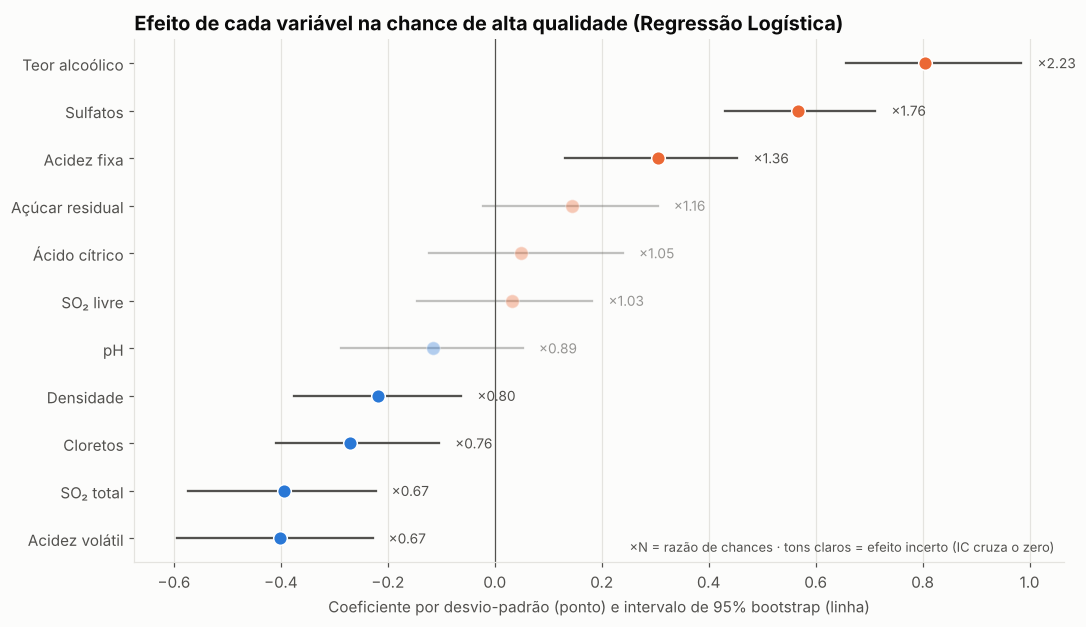

In [3]:
t = coef_tbl.sort_values("coeficiente")
fig, ax = plt.subplots(figsize=(10, 5.8))
colors = [COLOR_HIGH if v > 0 else COLOR_LOW for v in t["coeficiente"]]
alphas = [1.0 if s == "sim" else 0.35 for s in t["sinal_estável"]]
for i, (lab, row) in enumerate(t.iterrows()):
    ax.plot([row["IC95%_inf"], row["IC95%_sup"]], [i, i], color=INK_2, lw=1.5, alpha=alphas[i], zorder=1)
    ax.scatter(row["coeficiente"], i, s=80, color=colors[i], alpha=alphas[i], zorder=2, edgecolor="white", linewidth=1)
    ax.text(row["IC95%_sup"] + 0.03, i, f"×{row['razão_de_chances']:.2f}", va="center", color=INK_2, fontsize=9, alpha=max(alphas[i], 0.6))
ax.set_yticks(range(len(t)), t.index)
ax.axvline(0, color=INK_2, lw=0.8)
ax.set(title="Efeito de cada variável na chance de alta qualidade (Regressão Logística)",
       xlabel="Coeficiente por desvio-padrão (ponto) e intervalo de 95% bootstrap (linha)")
ax.grid(axis="y", visible=False)
ax.text(0.99, 0.02, "×N = razão de chances · tons claros = efeito incerto (IC cruza o zero)",
        transform=ax.transAxes, ha="right", fontsize=8.5, color=INK_2)
plt.tight_layout(); save_fig(fig, "17_coeficientes_logistica"); plt.show()

**Leitura:**

- **Teor alcoólico** é, de longe, o fator mais forte: cada desvio-padrão a mais (≈ 1 ponto percentual de álcool) **multiplica por ~2,2** a chance de o vinho ser de alta qualidade.
- **Sulfatos** vêm em segundo, multiplicando a chance por ~1,8.
- **Acidez volátil** e **SO₂ total** são os principais fatores negativos: cada desvio-padrão a mais **reduz a chance em ~1/3** (razão ≈ 0,67).
- **Cloretos** e **densidade** também reduzem a chance, com efeito menor.
- **Acidez fixa** aparece com efeito positivo estável (×1,36), embora fosse fraca na EDA. Isso é efeito da **multicolinearidade**: a acidez fixa está ligada ao pH e à densidade, e o modelo "divide" o efeito entre elas. Por isso esse coeficiente deve ser lido com cautela.
- **Açúcar residual, pH, ácido cítrico e SO₂ livre** têm intervalos que cruzam o zero: o modelo **não encontra efeito confiável** deles quando as outras variáveis já estão consideradas. O ácido cítrico, que parecia relevante na EDA, tem seu sinal "absorvido" pela acidez volátil e pelos sulfatos, com os quais é correlacionado.

## 6.2 Importância por permutação — os três modelos concordam?

Para cada variável, embaralhamos seus valores no **conjunto de teste** (quebrando a relação com a qualidade) e medimos quanto a PR-AUC cai. Quanto maior a queda, mais o modelo depende daquela variável. Repetimos 30 vezes por variável.

In [4]:
perm = {}
for name, pipe in tuned.items():
    r = permutation_importance(pipe, X_test, y_test, scoring="average_precision", n_repeats=30,
                               random_state=RANDOM_STATE, n_jobs=-1)
    perm[name] = pd.DataFrame({"importância": r.importances_mean, "desvio": r.importances_std}, index=X_test.columns)

imp = pd.DataFrame({MODEL_NAMES_PT[n]: d["importância"] for n, d in perm.items()})
ranks = imp.rank(ascending=False)
imp["ranking médio"] = ranks.mean(axis=1)
imp = imp.sort_values("ranking médio")
imp.index = [L[i] for i in imp.index]
imp.to_csv(RESULTS_DIR / "interpretacao_importancia_permutacao.csv")
imp

,Regressão Logística,Random Forest,Gradient Boosting,ranking médio
Teor alcoólico,0.248,0.260,0.273,1.000
Sulfatos,0.130,0.140,0.198,2.000
Acidez volátil,0.029,0.062,0.058,4.333
Densidade,0.022,0.052,0.081,4.667
SO₂ total,0.037,0.012,0.050,5.667
Açúcar residual,0.014,0.052,0.023,6.000
Cloretos,0.036,0.027,0.007,6.333
Ácido cítrico,-0.006,0.028,0.060,6.667
Acidez fixa,0.013,0.003,0.002,9.000
pH,-0.012,0.010,-0.008,10.000


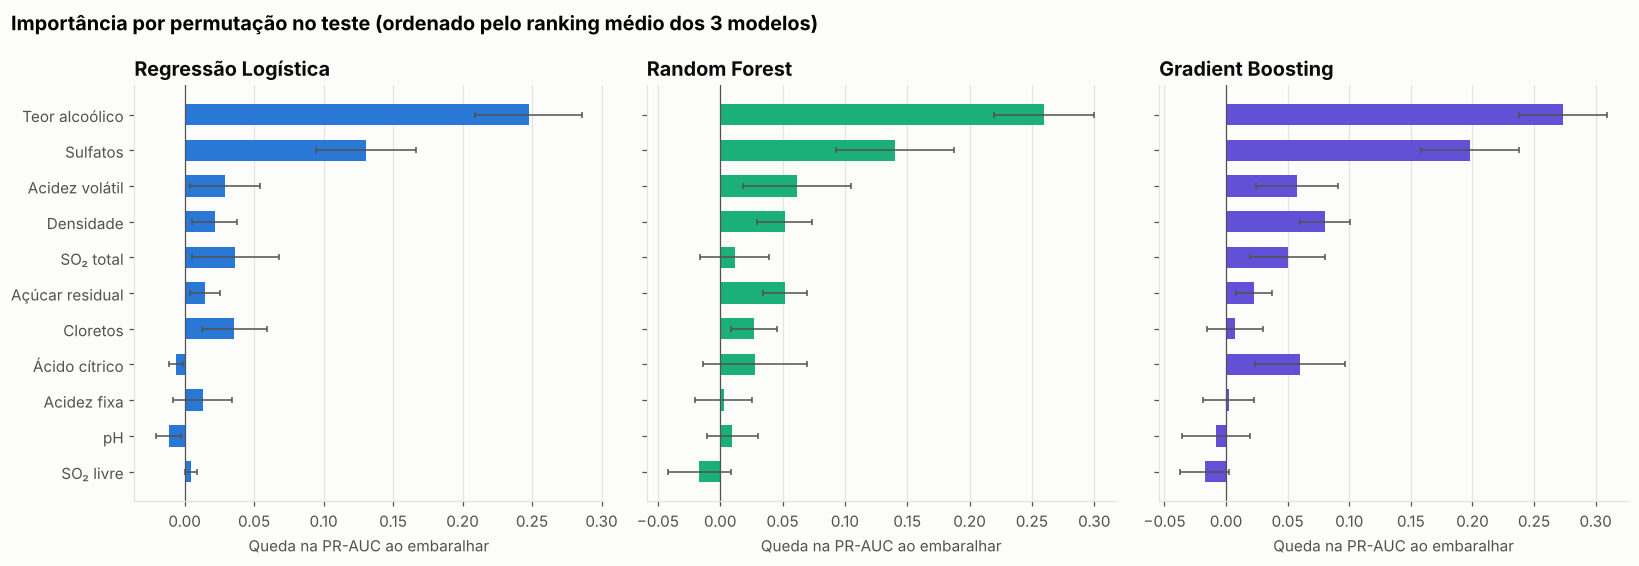

In [5]:
order = [i for i in imp.index][::-1]
inv = {v: k for k, v in L.items()}
fig, axes = plt.subplots(1, 3, figsize=(15, 5.2), sharey=True)
for ax, (name, d) in zip(axes, perm.items()):
    d = d.rename(index=L).reindex(order)
    ax.barh(d.index, d["importância"], xerr=d["desvio"], color=MODEL_COLORS[name], height=0.6,
            error_kw={"ecolor": INK_2, "lw": 1, "capsize": 2})
    ax.axvline(0, color=INK_2, lw=0.8)
    ax.set(title=MODEL_NAMES_PT[name], xlabel="Queda na PR-AUC ao embaralhar")
    ax.grid(axis="y", visible=False)
fig.suptitle("Importância por permutação no teste (ordenado pelo ranking médio dos 3 modelos)",
             x=0.01, ha="left", fontsize=13, fontweight="bold")
plt.tight_layout(); save_fig(fig, "18_importancia_permutacao"); plt.show()

**Leitura:**

- **Os três modelos concordam no topo:** **teor alcoólico** é a variável mais importante em todos, seguido de **sulfatos**. Embaralhar o álcool derruba a PR-AUC em ~0,25 — sozinho, ele responde por boa parte da capacidade de previsão.
- **Acidez volátil, densidade, SO₂ total, açúcar residual e cloretos** formam um segundo bloco, com importância moderada e ordem que varia entre os modelos.
- **pH, SO₂ livre e acidez fixa** contribuem pouco em todos os modelos; o **ácido cítrico** só tem algum peso no Gradient Boosting.
- Os modelos de árvore dão mais peso à **densidade** e ao **açúcar residual**, porque conseguem usá-los em combinações não lineares (a densidade "resume" álcool, açúcar e acidez).

**Conclusão:** o achado é **robusto** — modelos com lógicas completamente diferentes (linear e árvores) apontam o mesmo núcleo de variáveis. Isso reforça o que a EDA já indicava.

## 6.3 Simulações "e se": quanto cada fator move a pontuação?

Partimos de um **vinho típico** (mediana de cada variável no treino) e alteramos uma característica por vez, mantendo as outras fixas.

> **Nota técnica:** o modelo foi treinado com pesos de classe, então sua saída é uma **pontuação de 0 a 1**, não uma probabilidade calibrada. O que importa é a comparação com o **limiar de decisão** (acima dele → "alta qualidade") e a direção das mudanças.

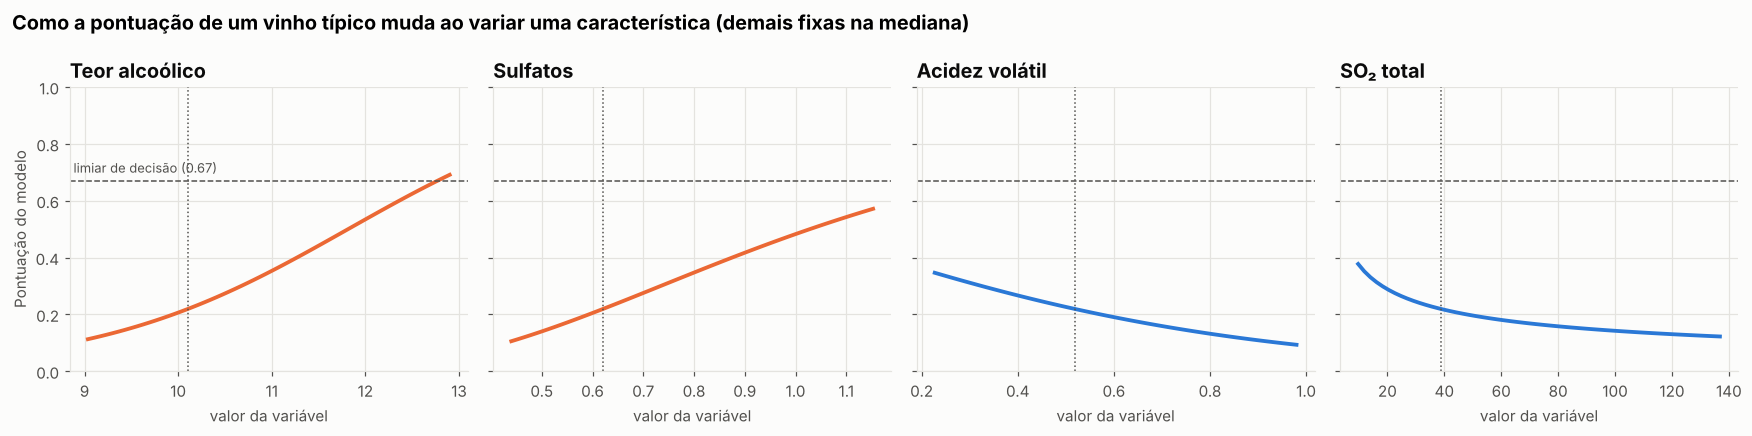

In [6]:
typical = X_train.median()
score = lambda row: final.predict_proba(pd.DataFrame([row])[FEATS])[:, 1][0]

curve_vars = ["alcohol", "sulphates", "volatile acidity", "total sulfur dioxide"]
fig, axes = plt.subplots(1, 4, figsize=(16, 4), sharey=True)
for ax, col in zip(axes, curve_vars):
    lo, hi = X_train[col].quantile([0.02, 0.98])
    grid = np.linspace(lo, hi, 60)
    s = [score(typical.copy().where(typical.index != col, v)) for v in grid]
    ax.plot(grid, s, color=COLOR_HIGH if final.named_steps["model"].coef_[0][list(names).index(col)] > 0 else COLOR_LOW, lw=2.5)
    ax.axhline(THR, color=INK_2, ls="--", lw=1)
    ax.axvline(typical[col], color=INK_2, ls=":", lw=1)
    ax.set(title=L[col], xlabel="valor da variável", ylim=(0, 1))
axes[0].set_ylabel("Pontuação do modelo")
axes[0].text(axes[0].get_xlim()[0], THR + 0.03, f" limiar de decisão ({THR:.2f})", color=INK_2, fontsize=8.5)
fig.suptitle("Como a pontuação de um vinho típico muda ao variar uma característica (demais fixas na mediana)",
             x=0.01, ha="left", fontsize=13, fontweight="bold")
plt.tight_layout(); save_fig(fig, "19_simulacao_curvas"); plt.show()

In [7]:
# Alavancas: levar cada variável do valor típico ao valor típico dos vinhos de alta qualidade
target = X_train[y_train == 1].median()
levers = ["alcohol", "sulphates", "volatile acidity", "total sulfur dioxide", "chlorides"]
rows = [{"cenário": "Vinho típico (mediana geral)", "pontuação": score(typical)}]
for col in levers:
    r = typical.copy(); r[col] = target[col]
    rows.append({"cenário": f"{L[col]}: {typical[col]:g} → {target[col]:g}", "pontuação": score(r)})
cum = typical.copy()
for col in levers: cum[col] = target[col]
rows.append({"cenário": "Todas as 5 alavancas juntas", "pontuação": score(cum)})
sim = pd.DataFrame(rows)
sim["variação vs típico"] = sim["pontuação"] - sim.loc[0, "pontuação"]
sim["classificação"] = np.where(sim["pontuação"] >= THR, "ALTA qualidade", "baixa/média")
sim.to_csv(RESULTS_DIR / "interpretacao_simulacao.csv", index=False)
sim

,cenário,pontuação,variação vs típico,classificação
0,Vinho típico (mediana geral),0.219,0.000,baixa/média
1,Teor alcoólico: 10.1 → 11.6,0.460,0.241,baixa/média
2,Sulfatos: 0.62 → 0.74,0.304,0.085,baixa/média
3,Acidez volátil: 0.52 → 0.37,0.280,0.061,baixa/média
4,SO₂ total: 39 → 27,0.256,0.037,baixa/média
5,Cloretos: 0.079 → 0.073,0.230,0.011,baixa/média
6,Todas as 5 alavancas juntas,0.707,0.488,ALTA qualidade


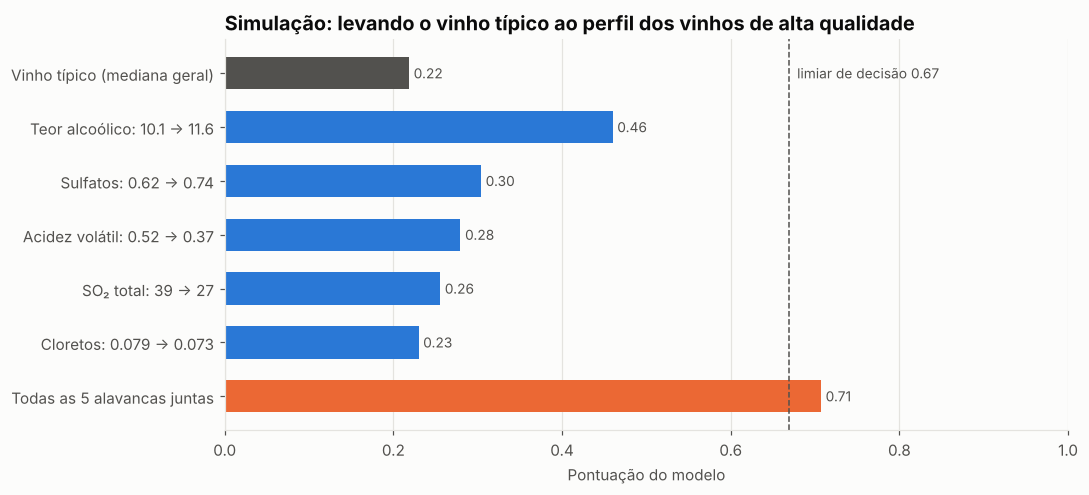

In [8]:
fig, ax = plt.subplots(figsize=(10, 4.6))
s = sim.iloc[::-1]
cols = [COLOR_HIGH if c == "ALTA qualidade" else (INK_2 if i == len(s) - 1 else COLOR_LOW) for i, c in enumerate(s["classificação"])]
bars = ax.barh(s["cenário"], s["pontuação"], color=cols, height=0.6)
ax.bar_label(bars, fmt="%.2f", padding=3, color=INK_2, fontsize=9)
ax.axvline(THR, color=INK_2, ls="--", lw=1)
ax.text(THR + 0.01, len(s) - 1, f"limiar de decisão {THR:.2f}", color=INK_2, fontsize=9, va="center")
ax.set(title="Simulação: levando o vinho típico ao perfil dos vinhos de alta qualidade", xlabel="Pontuação do modelo", xlim=(0, 1))
ax.grid(axis="y", visible=False)
plt.tight_layout(); save_fig(fig, "20_simulacao_alavancas"); plt.show()

**Leitura:**

- Um **vinho típico** tem pontuação ≈ 0,22 — bem abaixo do limiar (0,67).
- **Nenhuma alavanca isolada** é suficiente. A mais poderosa é o **teor alcoólico**: subir de 10,1% para 11,6% (o típico dos vinhos excelentes) **dobra** a pontuação, para ≈ 0,46.
- **Sulfatos, acidez volátil e SO₂ total** sobem a pontuação entre 4 e 9 pontos cada; cloretos, só 1 ponto.
- **Combinando as 5 alavancas**, o vinho típico ultrapassa o limiar e passa a ser classificado como **alta qualidade**.

**Mensagem central:** a qualidade não vem de um único fator; é o resultado de **acertar várias etapas do processo ao mesmo tempo**.

---
## 6.4 Implicações para o processo de produção

> ⚠️ **Correlação não é causalidade.** O modelo aprendeu **associações** em vinhos já produzidos. As recomendações abaixo são **hipóteses fundamentadas na enologia** e devem ser validadas com testes controlados em lotes piloto antes de mudanças de processo.

| Variável | Efeito na qualidade | Etapa do processo | Implicação prática |
|---|---|---|---|
| **Teor alcoólico** ↑ | Mais forte (×2,2) | Colheita e fermentação | Álcool reflete a **maturação da uva** (mais açúcar) e uma **fermentação completa**. Ponto de colheita e controle da fermentação são as alavancas — não a adição de álcool. |
| **Sulfatos** ↑ | Forte (×1,8) | Conservação | Contribuem para a proteção antimicrobiana e antioxidante. Revisar a dosagem de sulfato de potássio **dentro dos limites legais**. |
| **Acidez volátil** ↓ | Forte negativo (×0,67) | Higiene e fermentação | É ácido acético — sinal de **contaminação bacteriana** ou oxidação. Controle de temperatura, higiene de tanques e barris e redução do contato com oxigênio. É o principal **indicador de alerta** em tempo real. |
| **SO₂ total** ↓ | Forte negativo (×0,67) | Sulfitagem | Excesso prejudica o aroma. Junto com o efeito positivo dos sulfatos, a mensagem é **proteger sem exagerar**: dosagem precisa, não máxima. |
| **Cloretos** ↓ | Moderado negativo | Matéria-prima / água | Teor de sal: pode vir do solo, da água de irrigação ou de processo. Monitorar a origem. |
| pH, SO₂ livre, ácido cítrico | Sem efeito confiável | — | Não devem ser prioridade para melhorar a qualidade, quando as demais variáveis já são controladas. |

### Como o modelo pode ser usado no dia a dia

1. **Triagem de lotes:** analisar as medidas de laboratório de cada lote e sinalizar os com maior potencial de alta qualidade — priorizando a **degustação dos especialistas**, que continua sendo a decisão final.
2. **Alerta precoce:** monitorar acidez volátil e SO₂ durante a produção; desvios em relação ao perfil dos vinhos excelentes indicam lotes em risco, **antes do engarrafamento**.
3. **Limiar ajustável conforme a estratégia:** um produtor que não quer perder nenhum lote premium pode baixar o limiar (mais recall); quem precisa evitar classificar como premium um vinho comum pode subi-lo (mais precisão).
4. **Padronização:** usar o perfil físico-químico dos vinhos de alta qualidade (álcool ≈ 11,6%, acidez volátil ≈ 0,37, sulfatos ≈ 0,74) como **referência de controle de processo**.

### Limitações
- Base pequena e de uma única região e tipo (Vinho Verde tinto); generalizar para outros vinhos exige novos dados.
- Não há informação de uva, safra, terroir, envelhecimento ou preço — fatores que também influenciam a nota.
- A nota dos especialistas é subjetiva; o modelo herda esse ruído.

---
## Resumo da interpretação

1. **Teor alcoólico** é o fator mais importante — confirmado pelos coeficientes, pelos três modelos e pelas simulações.
2. **Sulfatos** (positivo), **acidez volátil** e **SO₂ total** (negativos) completam o núcleo das variáveis mais influentes.
3. O achado é **robusto**: modelos lineares e de árvore concordam.
4. **Nenhum fator isolado basta** — a alta qualidade é resultado de várias etapas bem executadas.
5. Uso recomendado: **triagem e alerta precoce**, apoiando — não substituindo — a avaliação dos enólogos.